In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
# Cell 2: Load & combine CSV files (same as before)
data_dir = r"C:\Users\Riya\Documents\heritage-predictor\env\Data"
dfs = []

for file in os.listdir(data_dir):
    if file.endswith(".csv"):
        city = file.replace(".csv", "")
        df = pd.read_csv(os.path.join(data_dir, file))
        df['City'] = city
        dfs.append(df)

data = pd.concat(dfs, ignore_index=True)
data["Datetime"] = pd.to_datetime(data["Datetime"], dayfirst=True, errors="coerce")
data = data.sort_values(['City', 'Datetime']).reset_index(drop=True)

In [3]:
# Cell 3: Simplified Feature Engineering
# Focus on essential features that work well with sequences
data['hour'] = data['Datetime'].dt.hour
data['dayofweek'] = data['Datetime'].dt.dayofweek
data['month'] = data['Datetime'].dt.month

# Cyclical encoding
data['hour_sin'] = np.sin(2 * np.pi * data['hour'] / 24)
data['hour_cos'] = np.cos(2 * np.pi * data['hour'] / 24)
data['day_sin'] = np.sin(2 * np.pi * data['dayofweek'] / 7)
data['day_cos'] = np.cos(2 * np.pi * data['dayofweek'] / 7)
data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)

# One-hot encode cities
data = pd.get_dummies(data, columns=['City'], drop_first=True)

# Select features (let LSTM learn temporal patterns instead of manual lag features)
feature_cols = ['Outdoor_Temp', 'Outdoor_Humidity', 'hour_sin', 'hour_cos', 
                'day_sin', 'day_cos', 'month_sin', 'month_cos'] + \
               [col for col in data.columns if col.startswith('City_')]

# Remove any rows with NaN values
data = data.dropna().reset_index(drop=True)

print("Feature engineering complete. Shape:", data.shape)
print("Features:", feature_cols)

Feature engineering complete. Shape: (31598, 32)
Features: ['Outdoor_Temp', 'Outdoor_Humidity', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'month_sin', 'month_cos', 'City_Barcelona02', 'City_Barcelona03', 'City_Bath', 'City_Bath02', 'City_Bath03', 'City_Dubai', 'City_Dubai02', 'City_Dubai03', 'City_Edinburgh', 'City_Gatwick', 'City_Gatwick02', 'City_Gatwick03', 'City_Norway', 'City_Norway02', 'City_Norway03', 'City_Singapore', 'City_Singapore02', 'City_Singapore03']


In [4]:
# Cell 4: Create sequences for LSTM
def create_sequences(data, feature_cols, target_cols, sequence_length=24):
    """
    Create sequences for LSTM training
    sequence_length: number of time steps to look back
    """
    sequences = []
    targets = []
    
    # Group by city to maintain temporal continuity within cities
    for city_data in data.groupby([col for col in data.columns if col.startswith('City_')]):
        city_df = city_data[1].sort_values('Datetime').reset_index(drop=True)
        
        # Extract features and targets
        X = city_df[feature_cols].values
        y = city_df[target_cols].values
        
        # Create sequences
        for i in range(len(X) - sequence_length):
            sequences.append(X[i:(i + sequence_length)])
            targets.append(y[i + sequence_length])
    
    return np.array(sequences), np.array(targets)

In [5]:
# Cell 5: Prepare data
sequence_length = 24  # Look back 24 hours
target_cols = ['Indoor_Temp', 'Indoor_Humidity']

print("Creating sequences...")
X_seq, y_seq = create_sequences(data, feature_cols, target_cols, sequence_length)

print(f"Sequences shape: {X_seq.shape}")
print(f"Targets shape: {y_seq.shape}")

# Scale the data
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Reshape for scaling (flatten sequences temporarily)
X_seq_flat = X_seq.reshape(-1, X_seq.shape[-1])
X_seq_scaled_flat = scaler_X.fit_transform(X_seq_flat)
X_seq_scaled = X_seq_scaled_flat.reshape(X_seq.shape)

y_seq_scaled = scaler_y.fit_transform(y_seq)

# Split data (maintain temporal order)
split_idx = int(0.8 * len(X_seq_scaled))
X_train = X_seq_scaled[:split_idx]
X_test = X_seq_scaled[split_idx:]
y_train = y_seq_scaled[:split_idx]
y_test = y_seq_scaled[split_idx:]

print(f"Training sequences: {X_train.shape}")
print(f"Test sequences: {X_test.shape}")

Creating sequences...
Sequences shape: (31502, 24, 26)
Targets shape: (31502, 2)
Training sequences: (25201, 24, 26)
Test sequences: (6301, 24, 26)


In [6]:
# Cell 6: Build improved LSTM model
model = Sequential([
    # Bidirectional LSTM to capture patterns in both directions
    Bidirectional(LSTM(128, return_sequences=True), 
                  input_shape=(sequence_length, len(feature_cols))),
    Dropout(0.3),
    
    # Second LSTM layer
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.3),
    
    # Dense layers
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(len(target_cols))  # Output layer
])

# Compile with better optimizer settings
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

print(model.summary())

c:\Users\Riya\Documents\heritage-predictor\env\Lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 256)        │       158,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,474 (1.27 MB)

 Trainable params: 333,474 (1.27 MB)

 Non-trainable params: 0 (0.00 B)

None


In [7]:
# Cell 7: Train with callbacks
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True, monitor='val_loss'),
    ReduceLROnPlateau(factor=0.5, patience=5, min_lr=1e-7, monitor='val_loss')
]

print("Training model...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)

Training model...
Epoch 1/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - loss: 0.1453 - mae: 0.2809 - val_loss: 0.4087 - val_mae: 0.5008 - learning_rate: 0.0010
Epoch 2/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - loss: 0.0910 - mae: 0.2201 - val_loss: 0.5179 - val_mae: 0.5456 - learning_rate: 0.0010
Epoch 3/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - loss: 0.0787 - mae: 0.2023 - val_loss: 0.5637 - val_mae: 0.5861 - learning_rate: 0.0010
Epoch 4/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - loss: 0.0724 - mae: 0.1929 - val_loss: 0.6252 - val_mae: 0.6174 - learning_rate: 0.0010
Epoch 5/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - loss: 0.0683 - mae: 0.1860 - val_loss: 0.5472 - val_mae: 0.5745 - learning_rate: 0.0010
Epoch 6/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - loss: 0.0645 - mae: 0.1802 - val_loss: 0.5796 - val_mae: 0.5916 - learning_rate: 0.0010
Epoch 7/100
394/394 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - loss: 0.0581 - mae: 0.1692 - val_loss: 0.6318 - val_mae

197/197 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Indoor_Temp - MAE: 4.129, RMSE: 5.395, R²: -0.143
Indoor_Humidity - MAE: 10.021, RMSE: 12.325, R²: -0.683


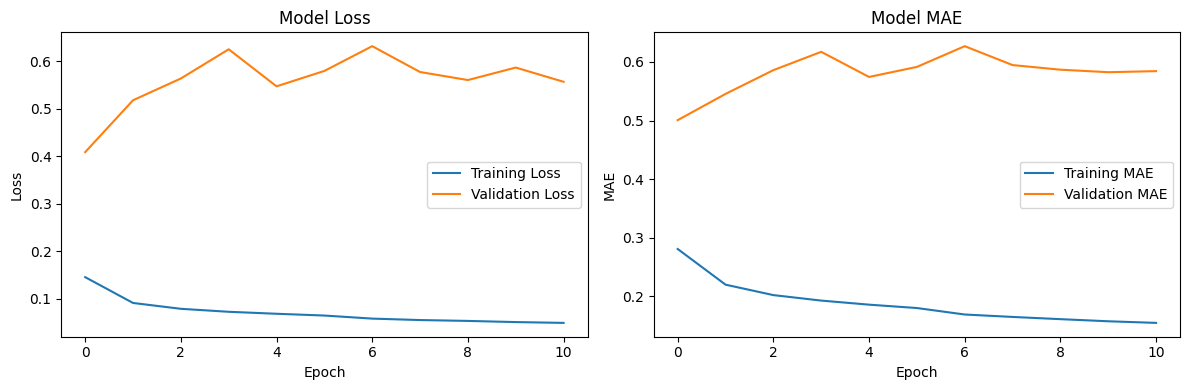

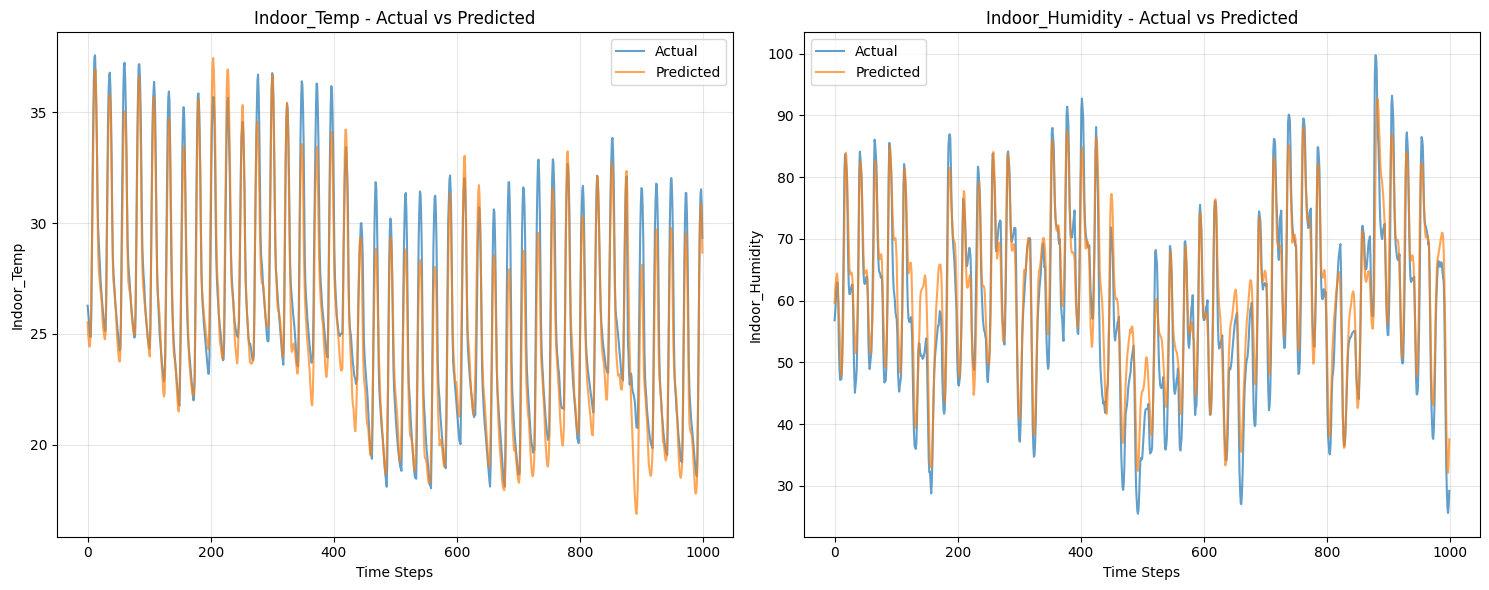

In [8]:
# Cell 8: Evaluation and visualization
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

# Calculate metrics
for i, col in enumerate(target_cols):
    mae = mean_absolute_error(y_test_inv[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_test_inv[:, i], y_pred[:, i]))
    r2 = r2_score(y_test_inv[:, i], y_pred[:, i])
    print(f"{col} - MAE: {mae:.3f}, RMSE: {rmse:.3f}, R²: {r2:.3f}")

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Model MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# Plot predictions vs actual
plt.figure(figsize=(15, 6))

for i, col in enumerate(target_cols):
    plt.subplot(1, 2, i+1)
    
    # Plot first 1000 points for visibility
    n_points = min(1000, len(y_test_inv))
    plt.plot(y_test_inv[:n_points, i], label='Actual', alpha=0.7)
    plt.plot(y_pred[:n_points, i], label='Predicted', alpha=0.7)
    
    plt.title(f'{col} - Actual vs Predicted')
    plt.xlabel('Time Steps')
    plt.ylabel(col)
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Calculating feature importance...
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
16/16 ━━━━━━━━━━━━━━

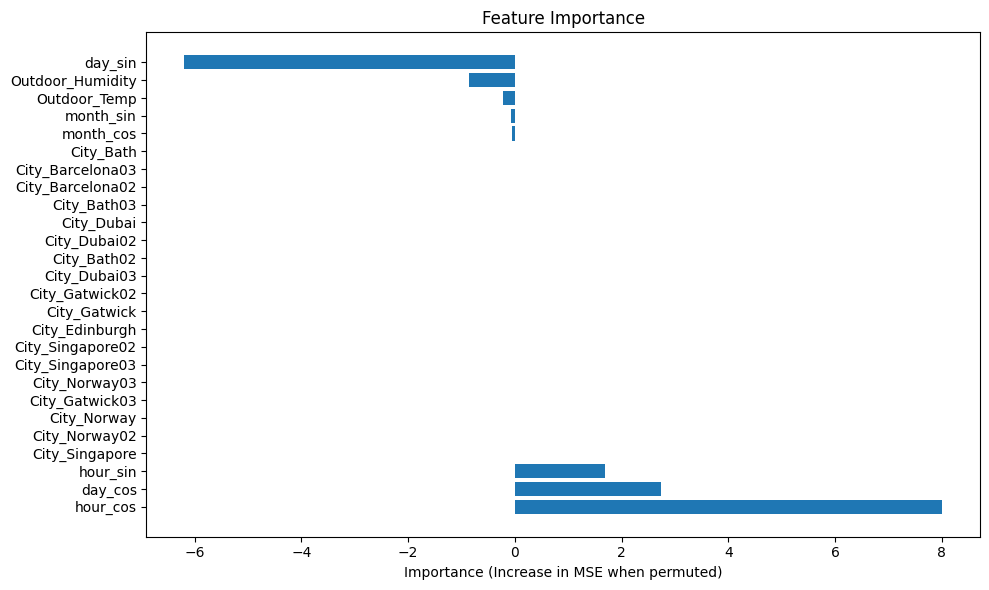

Model training and evaluation complete!


In [9]:
# Cell 9: Feature importance analysis (approximate)
def get_feature_importance_lstm(model, X_test, feature_names, n_samples=100):
    """
    Approximate feature importance by permutation
    """
    baseline_pred = model.predict(X_test[:n_samples])
    baseline_loss = np.mean((baseline_pred - scaler_y.inverse_transform(y_test[:n_samples]))**2)
    
    importances = []
    
    for i, feature in enumerate(feature_names):
        X_perm = X_test[:n_samples].copy()
        # Permute this feature across all time steps
        X_perm[:, :, i] = np.random.permutation(X_perm[:, :, i].flatten()).reshape(X_perm[:, :, i].shape)
        
        perm_pred = model.predict(X_perm)
        perm_loss = np.mean((perm_pred - scaler_y.inverse_transform(y_test[:n_samples]))**2)
        
        importance = perm_loss - baseline_loss
        importances.append(importance)
    
    return np.array(importances)

print("Calculating feature importance...")
importances = get_feature_importance_lstm(model, X_test, feature_cols, n_samples=500)

# Plot feature importance
plt.figure(figsize=(10, 6))
sorted_idx = np.argsort(importances)[::-1]
plt.barh(range(len(feature_cols)), importances[sorted_idx])
plt.yticks(range(len(feature_cols)), [feature_cols[i] for i in sorted_idx])
plt.xlabel('Importance (Increase in MSE when permuted)')
plt.title('Feature Importance')
plt.tight_layout()
plt.show()

print("Model training and evaluation complete!")